# Experiment 10 — Explore Visual Classification Using the k-NN Algorithm
**EoAI 2026–27 | CO6, CO8 | Google Colab**

**Aim:** Understand how a new point is classified based on nearby labelled examples.

**First:** File → **Save a copy in Drive** and name your copy `EoAI_Exp10_StudentID_Name.ipynb`.

**Evidence for your Google Doc:** (1) scatter plot of three labelled Iris classes, (2) test point with three nearest neighbours, (3) predictions for k = 1, 3, and 5. Add a brief comparison of your results.

## Step 1 — Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
print("Libraries loaded.")

Libraries loaded.


## Step 2 — Load and inspect Iris data

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame
cols = ["petal length (cm)", "petal width (cm)"]
X = df[cols]
y = df["target"]
print("IRIS PREVIEW")
print(df[cols + ["target"]].head().to_string(index=False))
print("Classes:", list(iris.target_names))

IRIS PREVIEW
 petal length (cm)  petal width (cm)  target
               1.4               0.2       0
               1.4               0.2       0
               1.3               0.2       0
               1.5               0.2       0
               1.4               0.2       0
Classes: ['setosa', 'versicolor', 'virginica']


## Step 3 — Display the labelled flower classes

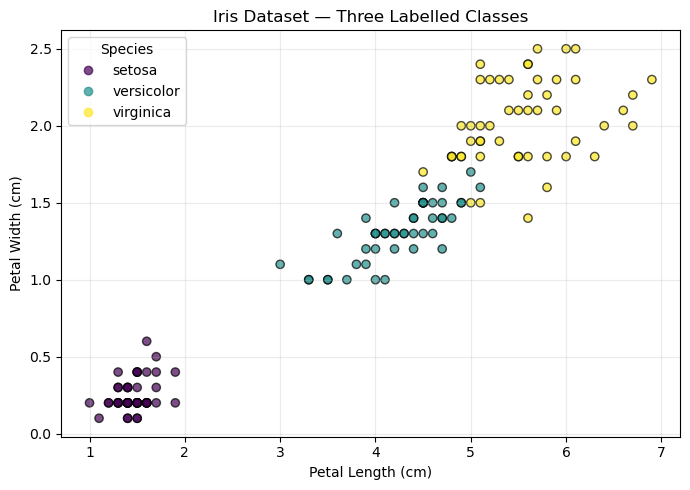

In [3]:
plt.figure(figsize=(7,5))
scatter = plt.scatter(X.iloc[:,0], X.iloc[:,1], c=y, cmap="viridis", edgecolors="black", alpha=0.7)
handles, _ = scatter.legend_elements()
plt.legend(handles, list(iris.target_names), title="Species")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Dataset — Three Labelled Classes")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Step 4 — Select a test point

Initially use petal length 4.5 cm and petal width 1.5 cm.

In [4]:
test_point = pd.DataFrame([[4.5,1.5]], columns=cols)
print("Test point:", test_point.iloc[0].to_dict())

Test point: {'petal length (cm)': 4.5, 'petal width (cm)': 1.5}


## Step 5 — Compare predicted species for k = 1, 3, and 5

In [5]:
predictions = {}
for k in [1,3,5]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X, y)
    species = iris.target_names[model.predict(test_point)[0]]
    predictions[k] = species
    print(f"k = {k}: {species}")
print("Did changing k change the prediction?", "Yes" if len(set(predictions.values())) > 1 else "No")

k = 1: versicolor
k = 3: versicolor
k = 5: versicolor
Did changing k change the prediction? No


## Step 6 — Plot the test point and its nearest neighbours (k = 3)

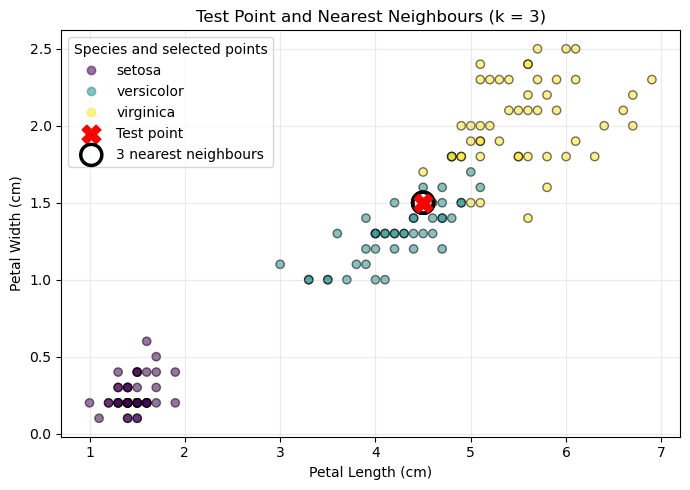

Nearest example row indices: [68, 51, 66]


In [6]:
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X,y)
distances, indices = model.kneighbors(test_point)
near = X.iloc[indices[0]]
plt.figure(figsize=(7,5))
scatter = plt.scatter(X.iloc[:,0], X.iloc[:,1], c=y, cmap="viridis", edgecolors="black", alpha=0.55)
test_marker = plt.scatter(test_point.iloc[0,0], test_point.iloc[0,1], c="red", marker="X", s=180, zorder=5)
near_marker = plt.scatter(near.iloc[:,0], near.iloc[:,1], facecolors="none", edgecolors="black", linewidths=2.5, s=230, zorder=4)
handles, _ = scatter.legend_elements()
plt.legend(handles + [test_marker, near_marker], list(iris.target_names) + ["Test point", "3 nearest neighbours"], title="Species and selected points")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Test Point and Nearest Neighbours (k = 3)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print("Nearest example row indices:", indices[0].tolist())

## Result / Observation

Write 2–3 lines explaining the predicted classes for k = 1, 3, and 5, whether they differ, and what the plot of nearest neighbours shows. Add the **three screenshots** to a new Experiment 10 page of your existing Google Doc. Save your Colab copy.